Dataset shape: (699635, 22)

Column names:
['Age', 'Flight Distance', 'Inflight wifi service', 'Departure/Arrival time convenient', 'Ease of Online booking', 'Gate location', 'Food and drink', 'Online boarding', 'Seat comfort', 'Inflight entertainment', 'On-board service', 'Leg room service', 'Baggage handling', 'Checkin service', 'Cleanliness', 'Departure Delay in Minutes', 'Arrival Delay in Minutes', 'Gender', 'Customer Type', 'Type of Travel', 'Class', 'satisfaction']

Class distribution:
satisfaction
False    389296
True     310339
Name: count, dtype: int64

Training samples: 559708
Testing samples: 139927

Training class proportions:
satisfaction
False    0.556428
True     0.443572
Name: proportion, dtype: float64

Testing class proportions:
satisfaction
False    0.556426
True     0.443574
Name: proportion, dtype: float64

CLEAN BASELINE RESULTS
accuracy: 0.8781
balanced_accuracy: 0.8749
f1: 0.8603
roc_auc: 0.9205

Running experiments for corruption rate: 0%

Running experiments f

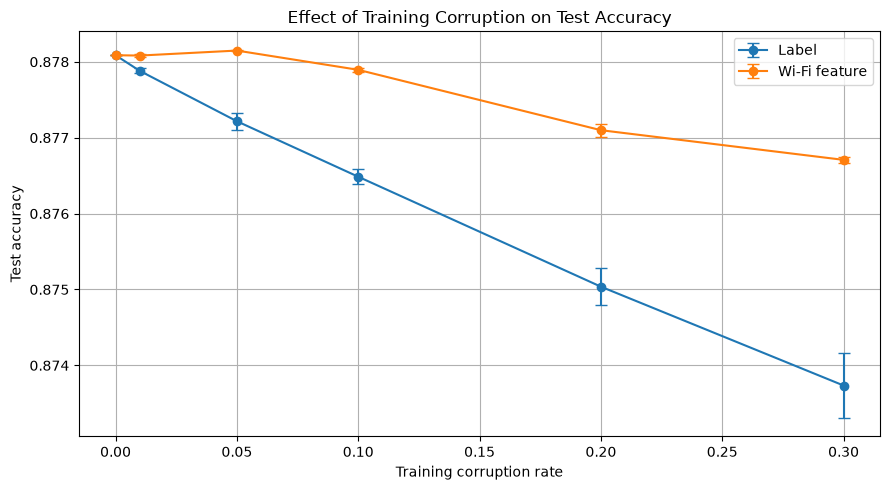

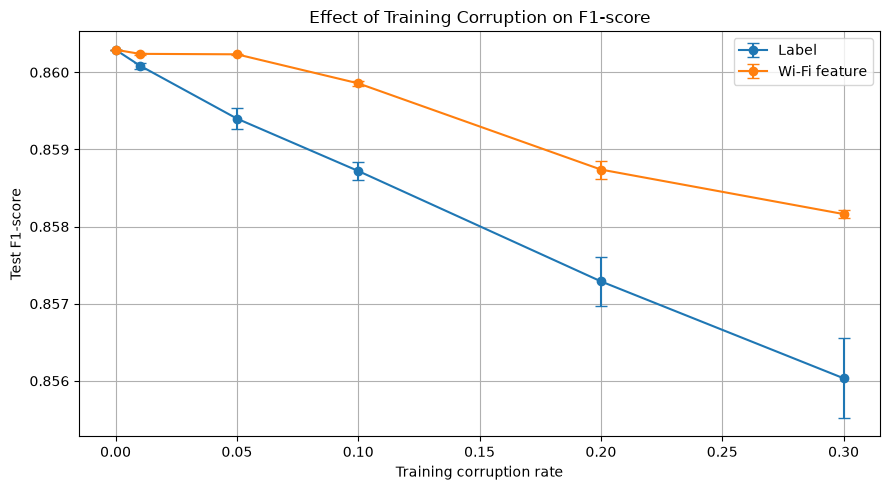

In [2]:

# ============================================================
# AIRLINE SATISFACTION CLASSIFICATION UNDER DATA CORRUPTION
# Logistic Regression: Label Corruption and Feature Corruption
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    roc_auc_score
)


# ============================================================
# 1. LOAD THE DATASET
# ============================================================

# Change the filename if your dataset has a different name.
df = pd.read_csv("train.csv")

# Remove accidental spaces from column names.
df.columns = df.columns.str.strip()

# Remove unnecessary index and identifier columns.
unnecessary_columns = [
    col for col in df.columns
    if col.lower() in ["id", "unnamed: 0"]
]

df = df.drop(columns=unnecessary_columns, errors="ignore")

# Target column
target = "satisfaction"

# Check whether the target exists.
if target not in df.columns:
    raise ValueError(
        f"Target column '{target}' not found.\n"
        f"Available columns: {df.columns.tolist()}"
    )

print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nClass distribution:")
print(df[target].value_counts())


# ============================================================
# 2. SEPARATE FEATURES AND TARGET
# ============================================================

X = df.drop(columns=[target]).copy()
y = df[target].copy()

# Confirm binary classification.
if y.nunique() != 2:
    raise ValueError(
        f"Expected binary classification, but found {y.nunique()} classes."
    )


# ============================================================
# 3. TRAIN-TEST SPLIT
# ============================================================

# Use the same clean test set for all experiments.
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nTraining samples:", len(X_train))
print("Testing samples:", len(X_test))

print("\nTraining class proportions:")
print(y_train.value_counts(normalize=True))

print("\nTesting class proportions:")
print(y_test.value_counts(normalize=True))


# ============================================================
# 4. PREPROCESSING AND MODEL
# ============================================================

numeric_columns = X_train.select_dtypes(
    include=np.number
).columns.tolist()

categorical_columns = X_train.select_dtypes(
    exclude=np.number
).columns.tolist()

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_columns),
    ("categorical", categorical_pipeline, categorical_columns)
])


def build_model():
    """Create a fresh logistic regression pipeline."""

    return Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", LogisticRegression(max_iter=2000))
    ])


# ============================================================
# 5. EVALUATION FUNCTION
# ============================================================

def evaluate_model(model, X_eval, y_eval):

    predictions = model.predict(X_eval)

    classifier = model.named_steps["classifier"]
    classes = list(classifier.classes_)

    # Use the 'satisfied' class as the positive class.
    # If that label is unavailable, use the second class.
    positive_label = (
        "satisfied" if "satisfied" in classes else classes[1]
    )

    positive_index = classes.index(positive_label)

    probabilities = model.predict_proba(X_eval)[:, positive_index]

    y_binary = (
        np.asarray(y_eval) == positive_label
    ).astype(int)

    return {
        "accuracy": accuracy_score(y_eval, predictions),

        "balanced_accuracy": balanced_accuracy_score(
            y_eval, predictions
        ),

        "f1": f1_score(
            y_eval,
            predictions,
            pos_label=positive_label,
            zero_division=0
        ),

        "roc_auc": roc_auc_score(
            y_binary,
            probabilities
        )
    }


# ============================================================
# 6. LABEL CORRUPTION
# ============================================================

def corrupt_labels(y, rate, seed):
    """
    Flip a specified proportion of binary training labels.

    rate = 0.10 means approximately 10% of labels are flipped.
    """

    rng = np.random.default_rng(seed)

    y_corrupted = y.reset_index(drop=True).copy()

    n = len(y_corrupted)
    n_corrupt = int(round(rate * n))

    indices = rng.choice(
        n,
        size=n_corrupt,
        replace=False
    )

    classes = y_corrupted.unique()

    if len(classes) != 2:
        raise ValueError("Label corruption requires two classes.")

    # Flip the selected labels.
    for idx in indices:

        current_label = y_corrupted.iloc[idx]

        other_label = next(
            label for label in classes
            if label != current_label
        )

        y_corrupted.iloc[idx] = other_label

    return y_corrupted


# ============================================================
# 7. FEATURE CORRUPTION
# ============================================================

def corrupt_wifi_feature(X, rate, seed):
    """
    Replace selected Inflight wifi service ratings with
    different randomly chosen values from 0, 1, 2, 3, 4, 5.

    Only the selected feature is modified.
    """

    rng = np.random.default_rng(seed)

    X_corrupted = X.copy()

    feature = "Inflight wifi service"

    if feature not in X_corrupted.columns:
        raise ValueError(
            f"Feature '{feature}' not found.\n"
            f"Available columns: {X_corrupted.columns.tolist()}"
        )

    n = len(X_corrupted)
    n_corrupt = int(round(rate * n))

    # Select observations without replacement.
    indices = rng.choice(
        n,
        size=n_corrupt,
        replace=False
    )

    # Read original ratings.
    original_values = X_corrupted[feature].to_numpy().copy()

    # Generate replacement ratings.
    new_values = rng.integers(
        low=0,
        high=6,
        size=n_corrupt
    )

    # Ensure each selected rating actually changes.
    old_values = original_values[indices]

    new_values = np.where(
        new_values == old_values,
        (new_values + 1) % 6,
        new_values
    )

    # Replace values at the selected positions.
    X_corrupted.iloc[
        indices,
        X_corrupted.columns.get_loc(feature)
    ] = new_values

    return X_corrupted


# ============================================================
# 8. CLEAN BASELINE MODEL
# ============================================================

baseline_model = build_model()

baseline_model.fit(X_train, y_train)

baseline_metrics = evaluate_model(
    baseline_model,
    X_test,
    y_test
)

print("\n" + "=" * 60)
print("CLEAN BASELINE RESULTS")
print("=" * 60)

for metric, value in baseline_metrics.items():
    print(f"{metric}: {value:.4f}")


# ============================================================
# 9. RUN CORRUPTION EXPERIMENTS
# ============================================================

corruption_rates = [0, 0.01, 0.05, 0.10, 0.20, 0.30]

n_repetitions = 10

results = []

for rate in corruption_rates:

    print(f"\nRunning experiments for corruption rate: {rate:.0%}")

    for repetition in range(n_repetitions):

        seed = 1000 + repetition

        # ----------------------------------------------------
        # EXPERIMENT A: LABEL CORRUPTION
        # ----------------------------------------------------

        y_noisy = corrupt_labels(
            y_train,
            rate,
            seed
        )

        model_label = build_model()

        model_label.fit(
            X_train,
            y_noisy
        )

        metrics_label = evaluate_model(
            model_label,
            X_test,
            y_test
        )

        results.append({
            "corruption_type": "Label",
            "rate": rate,
            "repetition": repetition,
            **metrics_label
        })

        # ----------------------------------------------------
        # EXPERIMENT B: FEATURE CORRUPTION
        # ----------------------------------------------------

        X_noisy = corrupt_wifi_feature(
            X_train,
            rate,
            seed
        )

        model_feature = build_model()

        model_feature.fit(
            X_noisy,
            y_train
        )

        metrics_feature = evaluate_model(
            model_feature,
            X_test,
            y_test
        )

        results.append({
            "corruption_type": "Wi-Fi feature",
            "rate": rate,
            "repetition": repetition,
            **metrics_feature
        })


# ============================================================
# 10. SUMMARIZE RESULTS
# ============================================================

results_df = pd.DataFrame(results)

metrics = [
    "accuracy",
    "balanced_accuracy",
    "f1",
    "roc_auc"
]

summary = (
    results_df
    .groupby(["corruption_type", "rate"])[metrics]
    .agg(["mean", "std"])
)

print("\n" + "=" * 60)
print("CORRUPTION EXPERIMENT RESULTS")
print("=" * 60)

print(summary.round(4).to_string())

# Save detailed results and summary.
results_df.to_csv(
    "corruption_results_all_runs.csv",
    index=False
)

summary.to_csv(
    "corruption_results_summary.csv"
)

print("\nResults saved to:")
print("1. corruption_results_all_runs.csv")
print("2. corruption_results_summary.csv")


# ============================================================
# 11. PLOT ACCURACY AGAINST CORRUPTION RATE
# ============================================================

plt.figure(figsize=(9, 5))

for corruption_type in results_df["corruption_type"].unique():

    subset = results_df[
        results_df["corruption_type"] == corruption_type
    ]

    grouped = subset.groupby("rate")["accuracy"]

    mean_accuracy = grouped.mean()
    std_accuracy = grouped.std()

    plt.errorbar(
        mean_accuracy.index,
        mean_accuracy.values,
        yerr=std_accuracy.values,
        marker="o",
        capsize=4,
        label=corruption_type
    )

plt.xlabel("Training corruption rate")
plt.ylabel("Test accuracy")
plt.title("Effect of Training Corruption on Test Accuracy")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


# ============================================================
# 12. PLOT F1-SCORE AGAINST CORRUPTION RATE
# ============================================================

plt.figure(figsize=(9, 5))

for corruption_type in results_df["corruption_type"].unique():

    subset = results_df[
        results_df["corruption_type"] == corruption_type
    ]

    grouped = subset.groupby("rate")["f1"]

    mean_f1 = grouped.mean()
    std_f1 = grouped.std()

    plt.errorbar(
        mean_f1.index,
        mean_f1.values,
        yerr=std_f1.values,
        marker="o",
        capsize=4,
        label=corruption_type
    )

plt.xlabel("Training corruption rate")
plt.ylabel("Test F1-score")
plt.title("Effect of Training Corruption on F1-score")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [3]:
# Check the actual label corruption rate

rate = 0.30

y_corrupted = corrupt_labels(
    y_train,
    rate,
    seed=1000
)

number_changed = np.sum(
    y_train.to_numpy() != y_corrupted.to_numpy()
)

actual_rate = number_changed / len(y_train)

print("Training samples:", len(y_train))
print("Labels changed:", number_changed)
print("Actual corruption rate:", actual_rate)

Training samples: 559708
Labels changed: 167912
Actual corruption rate: 0.29999928534164244


In [4]:
# Train on clean labels
clean_model = build_model()
clean_model.fit(X_train, y_train)

clean_predictions = clean_model.predict(X_test)

clean_accuracy = accuracy_score(
    y_test,
    clean_predictions
)

# Train on 30% corrupted labels
y_corrupted = corrupt_labels(
    y_train,
    rate=0.30,
    seed=1000
)

corrupted_model = build_model()
corrupted_model.fit(X_train, y_corrupted)

corrupted_predictions = corrupted_model.predict(X_test)

corrupted_accuracy = accuracy_score(
    y_test,
    corrupted_predictions
)

# Compare results
print("Clean accuracy:", clean_accuracy)
print("Corrupted accuracy:", corrupted_accuracy)

print(
    "Accuracy decrease:",
    clean_accuracy - corrupted_accuracy
)

print(
    "Percentage of test predictions that changed:",
    np.mean(clean_predictions != corrupted_predictions)
)

print(
    "Fraction of training labels corrupted:",
    np.mean(
        y_train.to_numpy() != y_corrupted.to_numpy()
    )
)

Clean accuracy: 0.8780864307817647
Corrupted accuracy: 0.873205314199547
Accuracy decrease: 0.004881116582217793
Percentage of test predictions that changed: 0.019460147076689988
Fraction of training labels corrupted: 0.29999928534164244


In [5]:
results_30 = []

for seed in range(20):

    y_noisy = corrupt_labels(
        y_train,
        rate=0.30,
        seed=seed
    )

    model = build_model()
    model.fit(X_train, y_noisy)

    metrics = calculate_metrics(
        model, X_test, y_test
    )

    results_30.append({
        "seed": seed,
        **metrics
    })

results_30 = pd.DataFrame(results_30)

print("Mean performance across 20 repetitions:")
print(results_30.drop(columns="seed").mean().round(4))

print("\nStandard deviation:")
print(results_30.drop(columns="seed").std().round(4))

NameError: name 'calculate_metrics' is not defined

Dataset shape: (699635, 23)

Feature shape: (699635, 21)
Target shape: (699635,)
Target classes: [0 1]

Numerical columns: ['Age', 'Flight Distance', 'Inflight wifi service', 'Departure/Arrival time convenient', 'Ease of Online booking', 'Gate location', 'Food and drink', 'Online boarding', 'Seat comfort', 'Inflight entertainment', 'On-board service', 'Leg room service', 'Baggage handling', 'Checkin service', 'Cleanliness', 'Departure Delay in Minutes', 'Arrival Delay in Minutes']

Categorical columns: ['Gender', 'Customer Type', 'Type of Travel', 'Class']

Training observations: 559708
Testing observations: 139927

CLEAN SVM RESULTS
Accuracy: 0.8762640519699557

LABEL CORRUPTION RESULTS

Clean Model Accuracy: 0.8762640519699557

  Corruption Rate (%)  Corrupted Samples  Accuracy  Accuracy Drop  Precision   Recall  F1 Score
                 5.0              27985  0.874749       0.001515   0.868762 0.845331  0.856886
                10.0              55970  0.873591       0.002673   0.

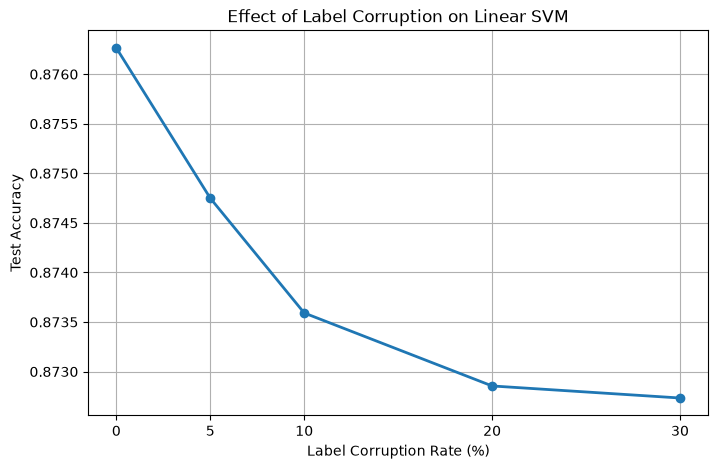

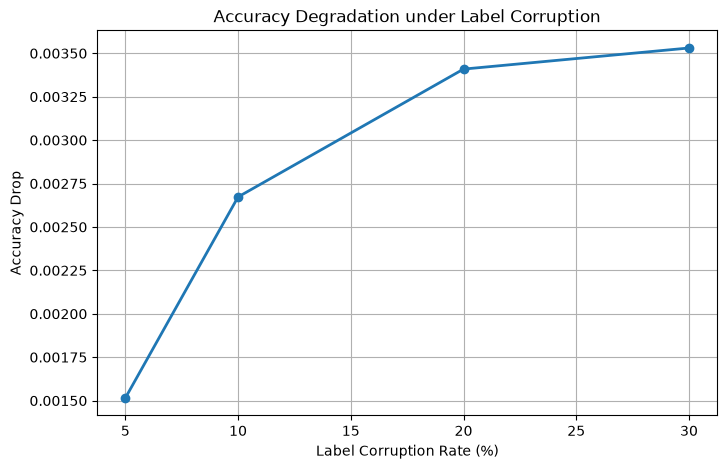

In [7]:

# ================================================
# SVM: EFFECT OF LABEL CORRUPTION
# ================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# ================================================
# 1. LOAD DATASET
# ================================================

df = pd.read_csv("train.csv")

print("Dataset shape:", df.shape)

# ================================================
# 2. SEPARATE FEATURES AND TARGET
# ================================================

# Remove ID and target columns
X = df.drop(columns=['id', 'satisfaction']).copy()

# Convert target TRUE/FALSE into 1/0
y = df['satisfaction'].astype(int)

print("\nFeature shape:", X.shape)
print("Target shape:", y.shape)
print("Target classes:", np.unique(y))

# ================================================
# 3. IDENTIFY CATEGORICAL AND NUMERICAL FEATURES
# ================================================

categorical_cols = [
    'Gender',
    'Customer Type',
    'Type of Travel',
    'Class'
]

numerical_cols = [
    col for col in X.columns
    if col not in categorical_cols
]

print("\nNumerical columns:", numerical_cols)
print("\nCategorical columns:", categorical_cols)

# ================================================
# 4. PREPROCESSING
# ================================================

numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numerical_cols),
        ('cat', categorical_transformer, categorical_cols)
    ]
)

# ================================================
# 5. TRAIN-TEST SPLIT
# ================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("\nTraining observations:", len(X_train))
print("Testing observations:", len(X_test))

# ================================================
# 6. DEFINE SVM MODEL
# ================================================

def build_svm():

    model = Pipeline(steps=[
        ('preprocessing', preprocessor),

        ('svm', LinearSVC(
            C=1.0,
            dual=False,
            max_iter=5000,
            random_state=42
        ))
    ])

    return model

# ================================================
# 7. TRAIN CLEAN SVM MODEL
# ================================================

clean_model = build_svm()

clean_model.fit(X_train, y_train)

clean_predictions = clean_model.predict(X_test)

clean_accuracy = accuracy_score(
    y_test,
    clean_predictions
)

print("\n================================")
print("CLEAN SVM RESULTS")
print("================================")

print("Accuracy:", clean_accuracy)

# ================================================
# 8. LABEL CORRUPTION EXPERIMENT
# ================================================

corruption_levels = [0.05, 0.10, 0.20, 0.30]

results = []

# Random number generator
rng = np.random.default_rng(42)

for rate in corruption_levels:

    # Copy original training labels
    y_corrupted = y_train.to_numpy().copy()

    # Number of labels to corrupt
    n_corrupt = int(rate * len(y_corrupted))

    # Randomly select observations
    indices = rng.choice(
        len(y_corrupted),
        size=n_corrupt,
        replace=False
    )

    # Flip binary labels: 0 -> 1 and 1 -> 0
    y_corrupted[indices] = 1 - y_corrupted[indices]

    # Build a new SVM model
    model = build_svm()

    # Train using corrupted labels
    model.fit(X_train, y_corrupted)

    # Predict on clean test data
    predictions = model.predict(X_test)

    # Calculate evaluation metrics
    accuracy = accuracy_score(y_test, predictions)

    precision = precision_score(
        y_test, predictions, zero_division=0
    )

    recall = recall_score(
        y_test, predictions, zero_division=0
    )

    f1 = f1_score(
        y_test, predictions, zero_division=0
    )

    # Store results
    results.append({

        'Corruption Rate (%)': rate * 100,

        'Corrupted Samples': n_corrupt,

        'Accuracy': accuracy,

        'Accuracy Drop': clean_accuracy - accuracy,

        'Precision': precision,

        'Recall': recall,

        'F1 Score': f1
    })

# ================================================
# 9. RESULTS TABLE
# ================================================

results_df = pd.DataFrame(results)

print("\n================================")
print("LABEL CORRUPTION RESULTS")
print("================================")

print("\nClean Model Accuracy:", clean_accuracy)

print("\n", results_df.to_string(index=False))

# ================================================
# 10. PLOT CORRUPTION VS ACCURACY
# ================================================

rates = [0] + results_df['Corruption Rate (%)'].tolist()

accuracies = (
    [clean_accuracy] +
    results_df['Accuracy'].tolist()
)

plt.figure(figsize=(8, 5))

plt.plot(
    rates,
    accuracies,
    marker='o',
    linewidth=2
)

plt.xlabel("Label Corruption Rate (%)")
plt.ylabel("Test Accuracy")

plt.title("Effect of Label Corruption on Linear SVM")

plt.xticks(rates)
plt.grid(True)

plt.show()

# ================================================
# 11. PLOT CORRUPTION VS ACCURACY DROP
# ================================================

plt.figure(figsize=(8, 5))

plt.plot(
    results_df['Corruption Rate (%)'],
    results_df['Accuracy Drop'],
    marker='o',
    linewidth=2
)

plt.xlabel("Label Corruption Rate (%)")
plt.ylabel("Accuracy Drop")

plt.title("Accuracy Degradation under Label Corruption")

plt.grid(True)

plt.show()


Total training samples: 559708
Total testing samples: 139927

TRAINING SAMPLE SIZE: 50000
Clean accuracy: 0.8762140258849257
Corruption: 20% | Accuracy: 0.87208 | Drop: 0.00414
Corruption: 30% | Accuracy: 0.87038 | Drop: 0.00583
Corruption: 40% | Accuracy: 0.86829 | Drop: 0.00793
Corruption: 50% | Accuracy: 0.56695 | Drop: 0.30926

TRAINING SAMPLE SIZE: 100000
Clean accuracy: 0.8761068271312898
Corruption: 20% | Accuracy: 0.87338 | Drop: 0.00272
Corruption: 30% | Accuracy: 0.87311 | Drop: 0.00300
Corruption: 40% | Accuracy: 0.86988 | Drop: 0.00622
Corruption: 50% | Accuracy: 0.54746 | Drop: 0.32864

TRAINING SAMPLE SIZE: 200000
Clean accuracy: 0.8758424035389882
Corruption: 20% | Accuracy: 0.87190 | Drop: 0.00394
Corruption: 30% | Accuracy: 0.87210 | Drop: 0.00374
Corruption: 40% | Accuracy: 0.87371 | Drop: 0.00214
Corruption: 50% | Accuracy: 0.57269 | Drop: 0.30315

TRAINING SAMPLE SIZE: 300000
Clean accuracy: 0.8760496544626841
Corruption: 20% | Accuracy: 0.87281 | Drop: 0.00324
Corr

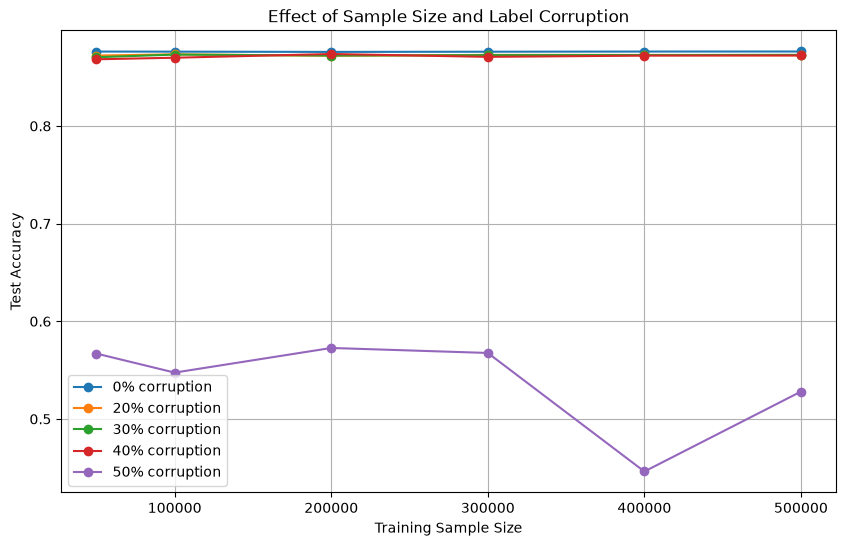

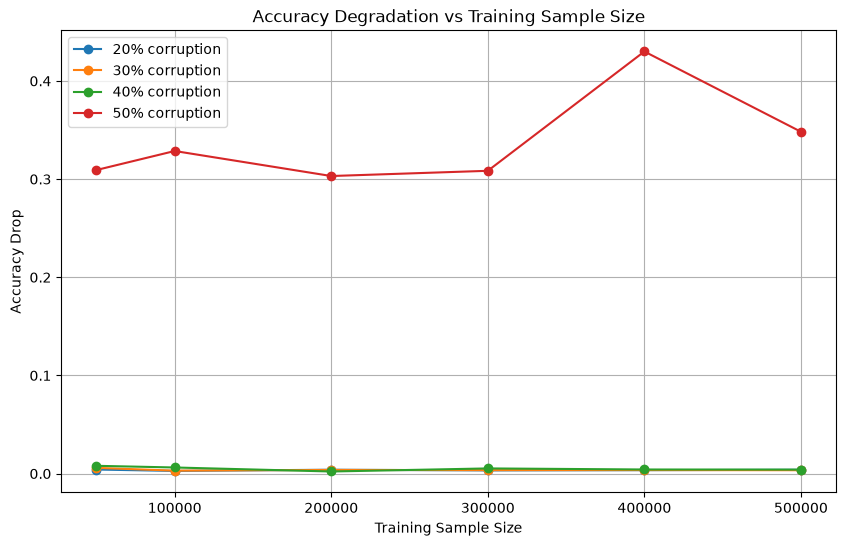


ACCURACY COMPARISON TABLE
Corruption (%)      0.0       20.0      30.0      40.0      50.0
Sample Size                                                     
50000           0.876214  0.872076  0.870382  0.868288  0.566953
100000          0.876107  0.873384  0.873105  0.869882  0.547464
200000          0.875842  0.871905  0.872098  0.873706  0.572691
300000          0.876050  0.872805  0.872534  0.870783  0.567582
400000          0.876214  0.872726  0.872634  0.872033  0.446197
500000          0.876264  0.872391  0.872834  0.872198  0.528011


In [1]:

# =====================================================
# EFFECT OF SAMPLE SIZE AND LABEL CORRUPTION ON SVM
# =====================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, f1_score

# =====================================================
# 1. LOAD DATASET
# =====================================================

df = pd.read_csv("train.csv")

# Remove ID and separate target
X = df.drop(columns=['id', 'satisfaction']).copy()
y = df['satisfaction'].astype(int)

# Categorical features
categorical_cols = [
    'Gender',
    'Customer Type',
    'Type of Travel',
    'Class'
]

numerical_cols = [
    col for col in X.columns
    if col not in categorical_cols
]

# =====================================================
# 2. TRAIN-TEST SPLIT
# =====================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Total training samples:", len(X_train))
print("Total testing samples:", len(X_test))

# =====================================================
# 3. PREPROCESSING
# =====================================================

def build_svm():

    numeric_transformer = Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler())
    ])

    categorical_transformer = Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('encoder', OneHotEncoder(handle_unknown='ignore'))
    ])

    preprocessor = ColumnTransformer([
        ('num', numeric_transformer, numerical_cols),
        ('cat', categorical_transformer, categorical_cols)
    ])

    model = Pipeline([
        ('preprocessing', preprocessor),
        ('svm', LinearSVC(
            C=1.0,
            dual=False,
            max_iter=5000,
            random_state=42
        ))
    ])

    return model

# =====================================================
# 4. SAMPLE SIZES AND CORRUPTION RATES
# =====================================================

sample_sizes = [
    50000,
    100000,
    200000,
    300000,
    400000,
    500000
]

corruption_levels = [
    0.00,
    0.20,
    0.30,
    0.40,
    0.50
]

# =====================================================
# 5. CREATE NESTED TRAINING SAMPLES
# =====================================================

# One random permutation ensures nested samples
rng = np.random.default_rng(42)

permutation = rng.permutation(len(X_train))

X_train_random = X_train.iloc[permutation].reset_index(drop=True)
y_train_random = y_train.iloc[permutation].reset_index(drop=True)

# =====================================================
# 6. EXPERIMENT
# =====================================================

results = []

for n in sample_sizes:

    print("\n====================================")
    print("TRAINING SAMPLE SIZE:", n)
    print("====================================")

    # Select first n observations
    X_subset = X_train_random.iloc[:n]

    y_subset = y_train_random.iloc[:n].to_numpy()

    # -------------------------------------
    # Clean model
    # -------------------------------------

    clean_model = build_svm()

    clean_model.fit(X_subset, y_subset)

    clean_predictions = clean_model.predict(X_test)

    clean_accuracy = accuracy_score(
        y_test, clean_predictions
    )

    clean_f1 = f1_score(
        y_test, clean_predictions
    )

    print("Clean accuracy:", clean_accuracy)

    # Store clean results
    results.append({
        'Sample Size': n,
        'Corruption (%)': 0,
        'Corrupted Samples': 0,
        'Accuracy': clean_accuracy,
        'Accuracy Drop': 0,
        'F1 Score': clean_f1
    })

    # -------------------------------------
    # Corrupted models
    # -------------------------------------

    for rate in corruption_levels[1:]:

        # Copy clean labels
        y_corrupted = y_subset.copy()

        # Number of corrupted observations
        n_corrupt = int(rate * n)

        # Independent random corruption
        noise_rng = np.random.default_rng(
            1000 + n + int(rate * 100)
        )

        indices = noise_rng.choice(
            n,
            size=n_corrupt,
            replace=False
        )

        # Flip labels: 0 -> 1, 1 -> 0
        y_corrupted[indices] = 1 - y_corrupted[indices]

        # Train corrupted SVM
        model = build_svm()

        model.fit(X_subset, y_corrupted)

        # Evaluate on the same clean test set
        predictions = model.predict(X_test)

        accuracy = accuracy_score(
            y_test, predictions
        )

        f1 = f1_score(
            y_test, predictions
        )

        accuracy_drop = clean_accuracy - accuracy

        print(
            f"Corruption: {rate*100:.0f}% | "
            f"Accuracy: {accuracy:.5f} | "
            f"Drop: {accuracy_drop:.5f}"
        )

        results.append({
            'Sample Size': n,
            'Corruption (%)': rate * 100,
            'Corrupted Samples': n_corrupt,
            'Accuracy': accuracy,
            'Accuracy Drop': accuracy_drop,
            'F1 Score': f1
        })

# =====================================================
# 7. RESULTS TABLE
# =====================================================

results_df = pd.DataFrame(results)

print("\n\nFINAL EXPERIMENTAL RESULTS")

print(
    results_df.to_string(index=False)
)

# =====================================================
# 8. ACCURACY VS SAMPLE SIZE
# =====================================================

plt.figure(figsize=(10, 6))

for rate in [0, 20, 30, 40, 50]:

    subset = results_df[
        results_df['Corruption (%)'] == rate
    ]

    plt.plot(
        subset['Sample Size'],
        subset['Accuracy'],
        marker='o',
        label=f'{rate}% corruption'
    )

plt.xlabel("Training Sample Size")
plt.ylabel("Test Accuracy")

plt.title("Effect of Sample Size and Label Corruption")

plt.legend()
plt.grid(True)
plt.show()

# =====================================================
# 9. ACCURACY DROP VS SAMPLE SIZE
# =====================================================

plt.figure(figsize=(10, 6))

for rate in [20, 30, 40, 50]:

    subset = results_df[
        results_df['Corruption (%)'] == rate
    ]

    plt.plot(
        subset['Sample Size'],
        subset['Accuracy Drop'],
        marker='o',
        label=f'{rate}% corruption'
    )

plt.xlabel("Training Sample Size")
plt.ylabel("Accuracy Drop")

plt.title("Accuracy Degradation vs Training Sample Size")

plt.legend()
plt.grid(True)
plt.show()

# =====================================================
# 10. PIVOT TABLE
# =====================================================

accuracy_table = results_df.pivot(
    index='Sample Size',
    columns='Corruption (%)',
    values='Accuracy'
)

print("\nACCURACY COMPARISON TABLE")

print(accuracy_table)


Training data: 559708
Testing data: 139927

SAMPLE SIZE: 1000
Clean accuracy: 0.8713
Corruption:   5.0% | Mean accuracy: 0.86976 | SD: 0.00209 | Drop: 0.00154
Corruption:  10.0% | Mean accuracy: 0.86538 | SD: 0.00360 | Drop: 0.00593
Corruption:  20.0% | Mean accuracy: 0.86044 | SD: 0.00384 | Drop: 0.01087
Corruption:  30.0% | Mean accuracy: 0.84315 | SD: 0.00932 | Drop: 0.02816
Corruption:  40.0% | Mean accuracy: 0.77437 | SD: 0.02570 | Drop: 0.09693
Corruption:  50.0% | Mean accuracy: 0.50925 | SD: 0.01792 | Drop: 0.36206

SAMPLE SIZE: 2000
Clean accuracy: 0.87657
Corruption:   5.0% | Mean accuracy: 0.87425 | SD: 0.00102 | Drop: 0.00232
Corruption:  10.0% | Mean accuracy: 0.87197 | SD: 0.00176 | Drop: 0.00460
Corruption:  20.0% | Mean accuracy: 0.86903 | SD: 0.00168 | Drop: 0.00754
Corruption:  30.0% | Mean accuracy: 0.85484 | SD: 0.00598 | Drop: 0.02173
Corruption:  40.0% | Mean accuracy: 0.79348 | SD: 0.02816 | Drop: 0.08309
Corruption:  50.0% | Mean accuracy: 0.52813 | SD: 0.06678 

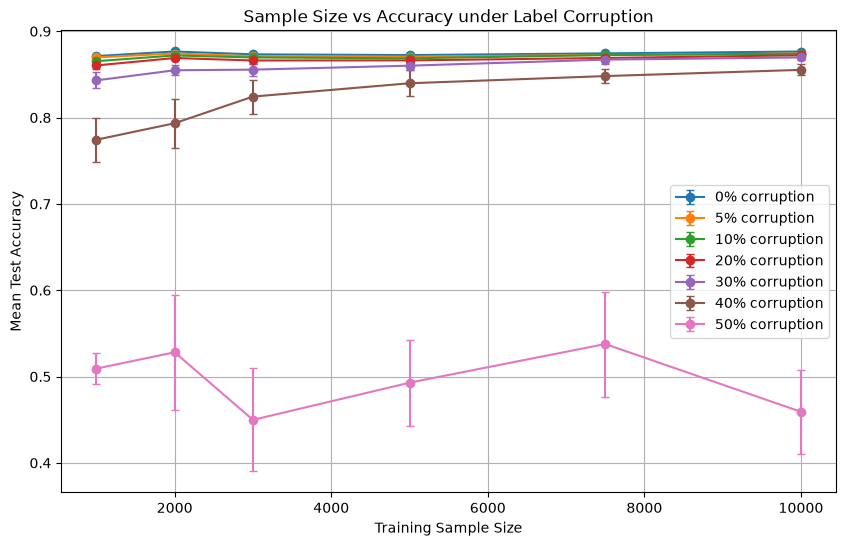

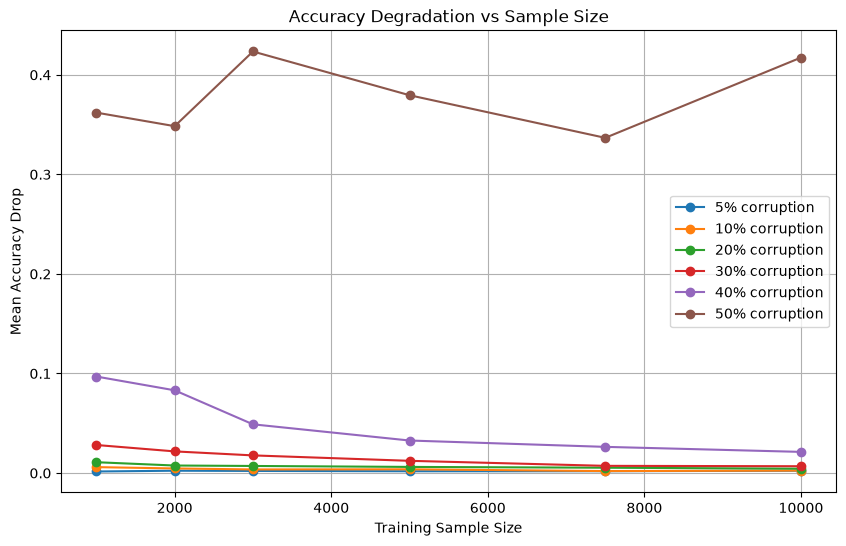


Results saved successfully.


In [9]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score

# =================================================
# 1. LOAD DATA
# =================================================

df = pd.read_csv("train.csv")

X = df.drop(columns=['id', 'satisfaction']).copy()
y = df['satisfaction'].astype(int)

categorical_cols = [
    'Gender',
    'Customer Type',
    'Type of Travel',
    'Class'
]

numerical_cols = [
    col for col in X.columns
    if col not in categorical_cols
]

# =================================================
# 2. FIXED TRAIN-TEST SPLIT
# =================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", len(X_train))
print("Testing data:", len(X_test))

# =================================================
# 3. BUILD SVM
# =================================================

def build_svm():

    numeric_transformer = Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler())
    ])

    categorical_transformer = Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('encoder', OneHotEncoder(handle_unknown='ignore'))
    ])

    preprocessor = ColumnTransformer([
        ('num', numeric_transformer, numerical_cols),
        ('cat', categorical_transformer, categorical_cols)
    ])

    model = Pipeline([
        ('preprocessing', preprocessor),
        ('svm', LinearSVC(
            C=1.0,
            dual=False,
            max_iter=5000,
            random_state=42
        ))
    ])

    return model

# =================================================
# 4. SAMPLE SIZES AND CORRUPTION RATES
# =================================================

sample_sizes = [
    1000,
    2000,
    3000,
    5000,
    7500,
    10000
]

corruption_levels = [
    0.00,
    0.05,
    0.10,
    0.20,
    0.30,
    0.40,
    0.50
]

REPETITIONS = 5

results = []

# =================================================
# 5. EXPERIMENT
# =================================================

for n in sample_sizes:

    print("\n====================================")
    print("SAMPLE SIZE:", n)
    print("====================================")

    # Select a stratified subset.
    # The same subset is used for every corruption level.

    X_subset, _, y_subset, _ = train_test_split(
        X_train,
        y_train,
        train_size=n,
        random_state=100 + n,
        stratify=y_train
    )

    y_subset = y_subset.to_numpy()

    # ---------------------------------------------
    # Clean model
    # ---------------------------------------------

    clean_model = build_svm()

    clean_model.fit(X_subset, y_subset)

    clean_predictions = clean_model.predict(X_test)

    clean_accuracy = accuracy_score(
        y_test,
        clean_predictions
    )

    print("Clean accuracy:", round(clean_accuracy, 5))

    # Store clean result
    results.append({
        'Sample Size': n,
        'Corruption (%)': 0,
        'Mean Accuracy': clean_accuracy,
        'Std Accuracy': 0,
        'Accuracy Drop': 0
    })

    # ---------------------------------------------
    # Corrupted models
    # ---------------------------------------------

    for rate in corruption_levels[1:]:

        accuracies = []

        for rep in range(REPETITIONS):

            # Copy original labels
            y_corrupted = y_subset.copy()

            # Number of corrupted labels
            n_corrupt = int(rate * n)

            # Independent corruption for each repetition
            rng = np.random.default_rng(
                100000 + n * 10 + int(rate * 1000) + rep
            )

            indices = rng.choice(
                n,
                size=n_corrupt,
                replace=False
            )

            # Flip labels
            y_corrupted[indices] = (
                1 - y_corrupted[indices]
            )

            # Train model
            model = build_svm()

            model.fit(X_subset, y_corrupted)

            # Evaluate on fixed clean test set
            predictions = model.predict(X_test)

            accuracy = accuracy_score(
                y_test,
                predictions
            )

            accuracies.append(accuracy)

        # Average over repetitions
        mean_accuracy = np.mean(accuracies)

        std_accuracy = np.std(
            accuracies,
            ddof=1
        )

        accuracy_drop = clean_accuracy - mean_accuracy

        print(
            f"Corruption: {rate*100:5.1f}% | "
            f"Mean accuracy: {mean_accuracy:.5f} | "
            f"SD: {std_accuracy:.5f} | "
            f"Drop: {accuracy_drop:.5f}"
        )

        results.append({
            'Sample Size': n,
            'Corruption (%)': rate * 100,
            'Mean Accuracy': mean_accuracy,
            'Std Accuracy': std_accuracy,
            'Accuracy Drop': accuracy_drop
        })

# =================================================
# 6. RESULTS TABLE
# =================================================

results_df = pd.DataFrame(results)

print("\n========== FINAL RESULTS ==========")

print(
    results_df.round(5).to_string(index=False)
)

# =================================================
# 7. ACCURACY TABLE
# =================================================

accuracy_table = results_df.pivot(
    index='Sample Size',
    columns='Corruption (%)',
    values='Mean Accuracy'
)

print("\nMEAN ACCURACY TABLE")

print(accuracy_table.round(5))

# =================================================
# 8. ACCURACY VS SAMPLE SIZE
# =================================================

plt.figure(figsize=(10, 6))

for rate in [0, 5, 10, 20, 30, 40, 50]:

    subset = results_df[
        results_df['Corruption (%)'] == rate
    ]

    plt.errorbar(
        subset['Sample Size'],
        subset['Mean Accuracy'],
        yerr=subset['Std Accuracy'],
        marker='o',
        capsize=3,
        label=f'{rate}% corruption'
    )

plt.xlabel("Training Sample Size")
plt.ylabel("Mean Test Accuracy")

plt.title("Sample Size vs Accuracy under Label Corruption")

plt.legend()
plt.grid(True)
plt.show()

# =================================================
# 9. ACCURACY DROP VS SAMPLE SIZE
# =================================================

plt.figure(figsize=(10, 6))

for rate in [5, 10, 20, 30, 40, 50]:

    subset = results_df[
        results_df['Corruption (%)'] == rate
    ]

    plt.plot(
        subset['Sample Size'],
        subset['Accuracy Drop'],
        marker='o',
        label=f'{rate}% corruption'
    )

plt.xlabel("Training Sample Size")
plt.ylabel("Mean Accuracy Drop")

plt.title("Accuracy Degradation vs Sample Size")

plt.legend()
plt.grid(True)
plt.show()

# =================================================
# 10. SAVE RESULTS
# =================================================

results_df.to_csv(
    "svm_small_sample_corruption_results.csv",
    index=False
)

print("\nResults saved successfully.")


Clean Model Accuracy: 0.8762640519699557

FEATURE IMPORTANCE RANKING
                          Feature  Importance      Std
                   Type of Travel    0.096433 0.001835
                  Online boarding    0.040567 0.001613
                    Customer Type    0.037900 0.001134
            Inflight wifi service    0.014033 0.000249
                 On-board service    0.007567 0.002001
                  Checkin service    0.007100 0.000748
                            Class    0.005567 0.000822
                      Cleanliness    0.003500 0.000653
                 Baggage handling    0.002900 0.000860
                 Leg room service    0.002600 0.000490
         Arrival Delay in Minutes    0.001667 0.000249
                              Age    0.000333 0.000573
                     Seat comfort    0.000033 0.000189
                   Food and drink    0.000000 0.000141
                  Flight Distance   -0.000067 0.000094
       Departure Delay in Minutes   -0.000333 0.000

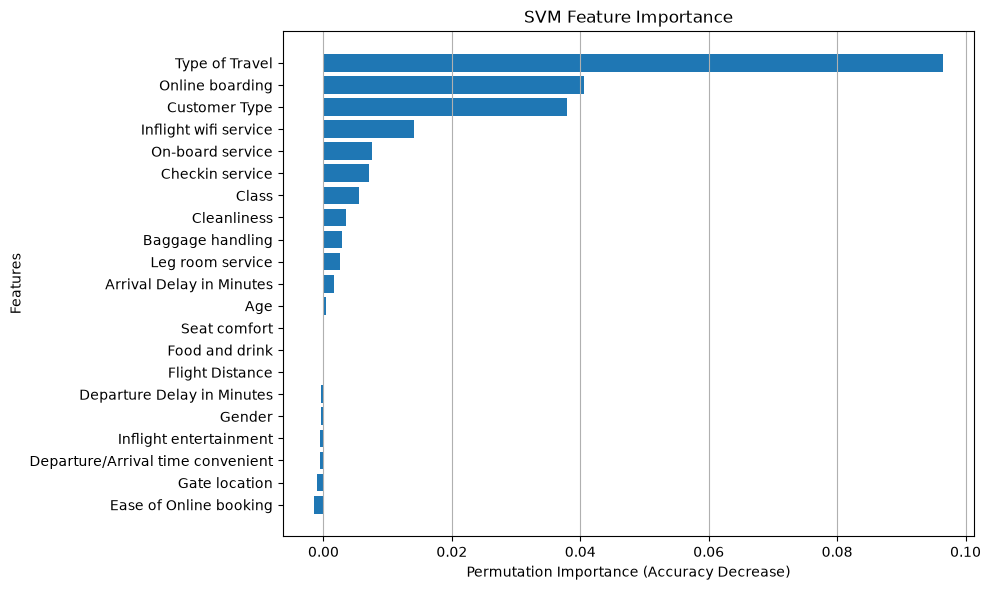

Corruption: 5.0% | Accuracy: 0.86847 | SD: 0.00010
Corruption: 10.0% | Accuracy: 0.85946 | SD: 0.00009
Corruption: 20.0% | Accuracy: 0.84613 | SD: 0.00004
Corruption: 30.0% | Accuracy: 0.83743 | SD: 0.00013
Corruption: 40.0% | Accuracy: 0.83195 | SD: 0.00013
Corruption: 50.0% | Accuracy: 0.82867 | SD: 0.00011

FEATURE CORRUPTION RESULTS

Clean Accuracy: 0.8762640519699557
 Corruption (%)  Mean Accuracy  Std Accuracy  Accuracy Drop
            5.0       0.868466      0.000100       0.007798
           10.0       0.859457      0.000094       0.016807
           20.0       0.846131      0.000039       0.030133
           30.0       0.837428      0.000132       0.038836
           40.0       0.831945      0.000131       0.044319
           50.0       0.828671      0.000108       0.047593


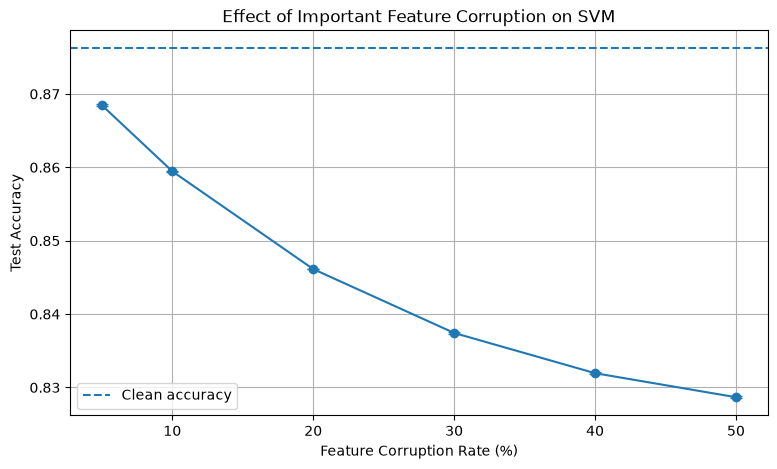

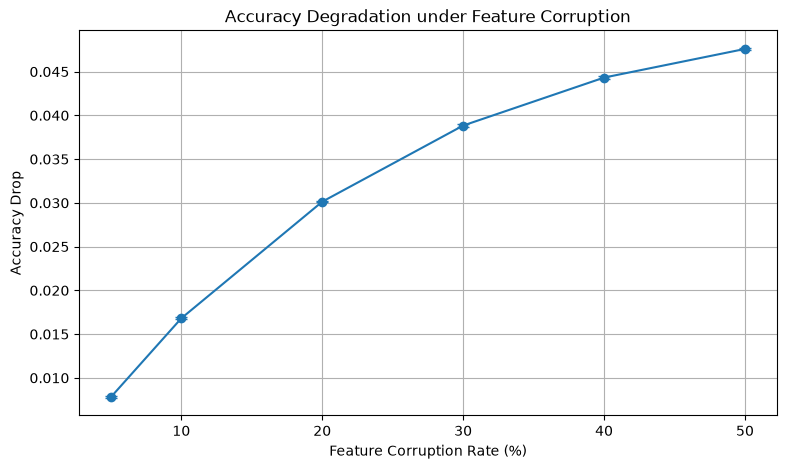


Results saved successfully.


In [2]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score
from sklearn.inspection import permutation_importance

# =====================================================
# 1. LOAD DATASET
# =====================================================

df = pd.read_csv("train.csv")

X = df.drop(columns=['id', 'satisfaction']).copy()
y = df['satisfaction'].astype(int)

categorical_cols = [
    'Gender',
    'Customer Type',
    'Type of Travel',
    'Class'
]

numerical_cols = [
    col for col in X.columns
    if col not in categorical_cols
]

# =====================================================
# 2. TRAIN-TEST SPLIT
# =====================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# =====================================================
# 3. PREPROCESSING
# =====================================================

def build_svm():

    numeric_transformer = Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler())
    ])

    categorical_transformer = Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('encoder', OneHotEncoder(handle_unknown='ignore'))
    ])

    preprocessor = ColumnTransformer([
        ('num', numeric_transformer, numerical_cols),
        ('cat', categorical_transformer, categorical_cols)
    ])

    return Pipeline([
        ('preprocessing', preprocessor),
        ('svm', LinearSVC(
            C=1.0,
            dual=False,
            max_iter=5000,
            random_state=42
        ))
    ])

# =====================================================
# 4. TRAIN CLEAN MODEL
# =====================================================

clean_model = build_svm()

clean_model.fit(X_train, y_train)

clean_predictions = clean_model.predict(X_test)

clean_accuracy = accuracy_score(
    y_test,
    clean_predictions
)

print("Clean Model Accuracy:", clean_accuracy)

# =====================================================
# 5. IDENTIFY IMPORTANT FEATURES
# =====================================================

# Use a representative subset of the test data
# to reduce computational cost.

importance_size = min(10000, len(X_test))

X_importance = X_test.sample(
    n=importance_size,
    random_state=42
)

y_importance = y_test.loc[X_importance.index]

importance_result = permutation_importance(
    clean_model,
    X_importance,
    y_importance,
    scoring='accuracy',
    n_repeats=3,
    random_state=42,
    n_jobs=-1
)

importance_df = pd.DataFrame({
    'Feature': X.columns,
    'Importance': importance_result.importances_mean,
    'Std': importance_result.importances_std
})

importance_df = importance_df.sort_values(
    by='Importance',
    ascending=False
)

print("\nFEATURE IMPORTANCE RANKING")
print(importance_df.to_string(index=False))

# Select top five features
top_features = importance_df.head(5)['Feature'].tolist()

print("\nTOP FIVE IMPORTANT FEATURES:")
print(top_features)

# =====================================================
# 6. PLOT FEATURE IMPORTANCE
# =====================================================

plt.figure(figsize=(10, 6))

plt.barh(
    importance_df['Feature'][::-1],
    importance_df['Importance'][::-1]
)

plt.xlabel("Permutation Importance (Accuracy Decrease)")
plt.ylabel("Features")

plt.title("SVM Feature Importance")

plt.grid(axis='x')
plt.tight_layout()
plt.show()

# =====================================================
# 7. FEATURE CORRUPTION FUNCTION
# =====================================================

def corrupt_features(X_original, features, rate, rng):

    X_corrupted = X_original.copy()

    n = len(X_corrupted)

    for feature in features:

        # Number of observations to corrupt
        n_corrupt = int(rate * n)

        # Randomly select observations
        indices = rng.choice(
            n,
            size=n_corrupt,
            replace=False
        )

        # Get valid observed values for this feature
        valid_values = X_original[feature].dropna().unique()

        # Cannot corrupt a feature with fewer than
        # two distinct valid values
        if len(valid_values) < 2:
            continue

        # Original values at selected positions
        old_values = X_corrupted[feature].iloc[indices].to_numpy()

        # Random replacement values
        new_values = rng.choice(
            valid_values,
            size=n_corrupt
        )

        # Ensure replacements differ from original values
        same = new_values == old_values

        while np.any(same):
            new_values[same] = rng.choice(
                valid_values,
                size=np.sum(same)
            )

            same = new_values == old_values

        # Replace feature values
        X_corrupted.iloc[
            indices,
            X_corrupted.columns.get_loc(feature)
        ] = new_values

    return X_corrupted

# =====================================================
# 8. CORRUPTION EXPERIMENT
# =====================================================

corruption_levels = [
    0.05,
    0.10,
    0.20,
    0.30,
    0.40,
    0.50
]

results = []

REPETITIONS = 5

for rate in corruption_levels:

    accuracies = []

    for rep in range(REPETITIONS):

        rng = np.random.default_rng(
            1000 + int(rate * 1000) + rep
        )

        # Corrupt only the top five features
        X_noisy = corrupt_features(
            X_train,
            top_features,
            rate,
            rng
        )

        # Train model
        model = build_svm()

        model.fit(X_noisy, y_train)

        # Test on original clean data
        predictions = model.predict(X_test)

        accuracy = accuracy_score(
            y_test,
            predictions
        )

        accuracies.append(accuracy)

    mean_accuracy = np.mean(accuracies)

    std_accuracy = np.std(
        accuracies,
        ddof=1
    )

    results.append({
        'Corruption (%)': rate * 100,
        'Mean Accuracy': mean_accuracy,
        'Std Accuracy': std_accuracy,
        'Accuracy Drop': clean_accuracy - mean_accuracy
    })

    print(
        f"Corruption: {rate*100}% | "
        f"Accuracy: {mean_accuracy:.5f} | "
        f"SD: {std_accuracy:.5f}"
    )

# =====================================================
# 9. DISPLAY RESULTS
# =====================================================

results_df = pd.DataFrame(results)

print("\nFEATURE CORRUPTION RESULTS")

print("\nClean Accuracy:", clean_accuracy)

print(results_df.to_string(index=False))

# =====================================================
# 10. PLOT ACCURACY VS CORRUPTION
# =====================================================

plt.figure(figsize=(9, 5))

plt.errorbar(
    results_df['Corruption (%)'],
    results_df['Mean Accuracy'],
    yerr=results_df['Std Accuracy'],
    marker='o',
    capsize=4
)

plt.axhline(
    clean_accuracy,
    linestyle='--',
    label='Clean accuracy'
)

plt.xlabel("Feature Corruption Rate (%)")
plt.ylabel("Test Accuracy")

plt.title("Effect of Important Feature Corruption on SVM")

plt.legend()
plt.grid(True)
plt.show()

# =====================================================
# 11. PLOT ACCURACY DEGRADATION
# =====================================================

plt.figure(figsize=(9, 5))

plt.errorbar(
    results_df['Corruption (%)'],
    results_df['Accuracy Drop'],
    yerr=results_df['Std Accuracy'],
    marker='o',
    capsize=4
)

plt.xlabel("Feature Corruption Rate (%)")
plt.ylabel("Accuracy Drop")

plt.title("Accuracy Degradation under Feature Corruption")

plt.grid(True)
plt.show()

# =====================================================
# 12. SAVE RESULTS
# =====================================================

results_df.to_csv(
    "svm_important_feature_corruption.csv",
    index=False
)

importance_df.to_csv(
    "svm_feature_importance.csv",
    index=False
)

print("\nResults saved successfully.")


Training samples: 559708
Testing samples: 139927

Identifying important features...

FEATURE IMPORTANCE RANKING
                          Feature  Importance      Std
                   Type of Travel    0.095467 0.001087
                  Online boarding    0.040700 0.001233
                    Customer Type    0.039233 0.002053
            Inflight wifi service    0.013433 0.001926
                 On-board service    0.008167 0.001250
                  Checkin service    0.005667 0.000967
                            Class    0.005333 0.000287
                      Cleanliness    0.003033 0.000858
                 Baggage handling    0.002833 0.000450
                 Leg room service    0.002267 0.001347
                    Gate location    0.001500 0.000216
                              Age    0.000833 0.000249
                     Seat comfort    0.000733 0.000287
         Arrival Delay in Minutes    0.000500 0.000424
           Inflight entertainment    0.000467 0.000309
Departur

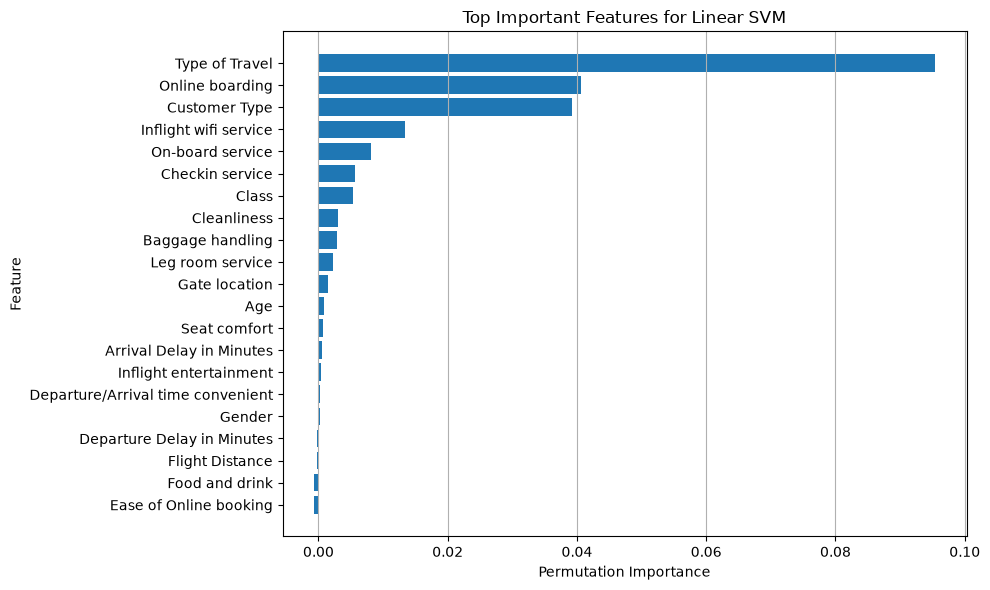


TRAINING SAMPLE SIZE: 1000
Clean accuracy: 0.8706468372794386
Corruption:  5% | Mean accuracy: 0.86119 | SD: 0.00100 | Drop: 0.00946
Corruption: 10% | Mean accuracy: 0.84973 | SD: 0.00571 | Drop: 0.02092
Corruption: 20% | Mean accuracy: 0.83801 | SD: 0.00391 | Drop: 0.03263
Corruption: 30% | Mean accuracy: 0.82719 | SD: 0.00239 | Drop: 0.04346
Corruption: 40% | Mean accuracy: 0.82488 | SD: 0.00201 | Drop: 0.04577
Corruption: 50% | Mean accuracy: 0.82400 | SD: 0.00320 | Drop: 0.04664

TRAINING SAMPLE SIZE: 2000
Clean accuracy: 0.872740786267125
Corruption:  5% | Mean accuracy: 0.86504 | SD: 0.00138 | Drop: 0.00770
Corruption: 10% | Mean accuracy: 0.85515 | SD: 0.00061 | Drop: 0.01759
Corruption: 20% | Mean accuracy: 0.84148 | SD: 0.00110 | Drop: 0.03126
Corruption: 30% | Mean accuracy: 0.83396 | SD: 0.00243 | Drop: 0.03878
Corruption: 40% | Mean accuracy: 0.83038 | SD: 0.00176 | Drop: 0.04236
Corruption: 50% | Mean accuracy: 0.82697 | SD: 0.00158 | Drop: 0.04577

TRAINING SAMPLE SIZE: 

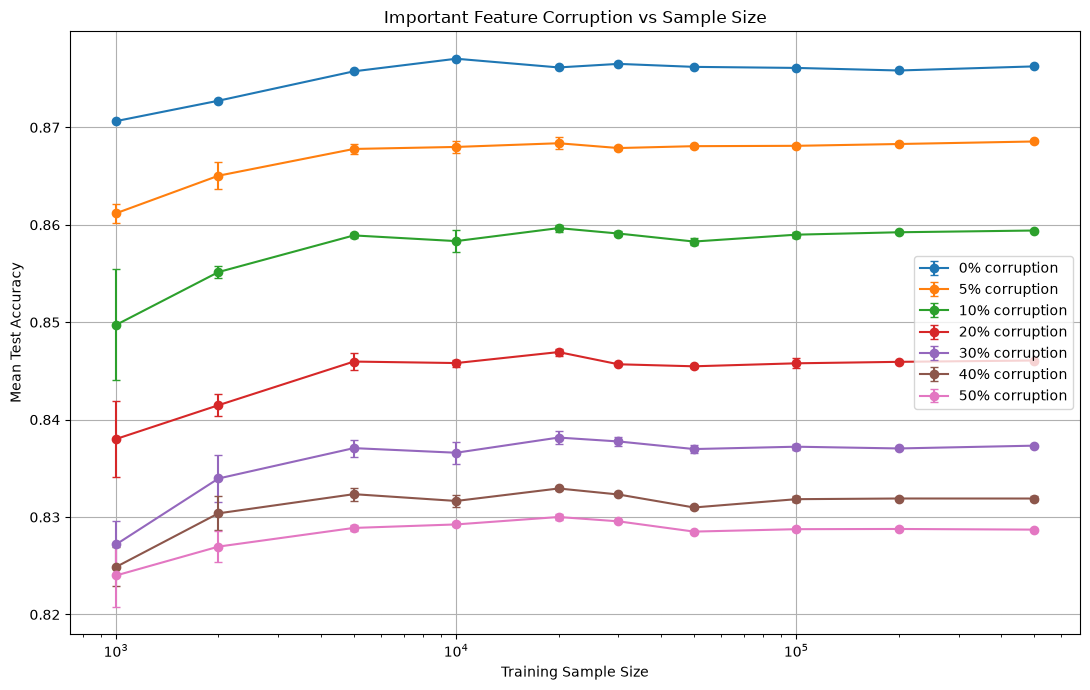

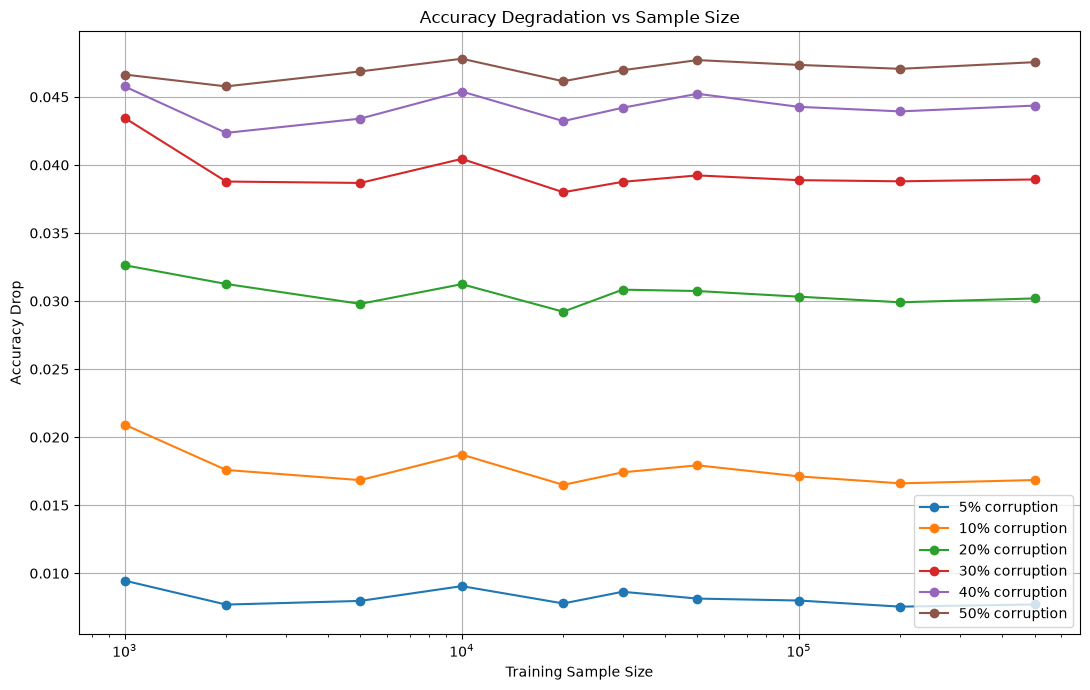


Results saved successfully.


In [3]:

# ============================================================
# FEATURE CORRUPTION EXPERIMENT: SAMPLE SIZE VS CORRUPTION
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score
from sklearn.inspection import permutation_importance

# ============================================================
# 1. LOAD DATASET
# ============================================================

df = pd.read_csv("train.csv")

X = df.drop(columns=['id', 'satisfaction']).copy()
y = df['satisfaction'].astype(int)

categorical_cols = [
    'Gender',
    'Customer Type',
    'Type of Travel',
    'Class'
]

numerical_cols = [
    col for col in X.columns
    if col not in categorical_cols
]

# ============================================================
# 2. TRAIN-TEST SPLIT
# ============================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

# ============================================================
# 3. BUILD SVM MODEL
# ============================================================

def build_svm():

    numeric_transformer = Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler())
    ])

    categorical_transformer = Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('encoder', OneHotEncoder(handle_unknown='ignore'))
    ])

    preprocessor = ColumnTransformer([
        ('num', numeric_transformer, numerical_cols),
        ('cat', categorical_transformer, categorical_cols)
    ])

    model = Pipeline([
        ('preprocessing', preprocessor),

        ('svm', LinearSVC(
            C=1.0,
            dual=False,
            max_iter=5000,
            random_state=42
        ))
    ])

    return model

# ============================================================
# 4. IDENTIFY TOP FIVE IMPORTANT FEATURES
# ============================================================

print("\nIdentifying important features...")

# Separate a validation subset from training data
X_fit, X_val, y_fit, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.2,
    random_state=123,
    stratify=y_train
)

importance_model = build_svm()

importance_model.fit(X_fit, y_fit)

# Use 10,000 validation observations for importance estimation
importance_size = min(10000, len(X_val))

X_importance = X_val.sample(
    n=importance_size,
    random_state=42
)

y_importance = y_val.loc[X_importance.index]

importance_result = permutation_importance(
    importance_model,
    X_importance,
    y_importance,
    scoring='accuracy',
    n_repeats=3,
    random_state=42,
    n_jobs=-1
)

importance_df = pd.DataFrame({
    'Feature': X.columns,
    'Importance': importance_result.importances_mean,
    'Std': importance_result.importances_std
})

importance_df = importance_df.sort_values(
    'Importance',
    ascending=False
)

top_features = importance_df.head(5)['Feature'].tolist()

print("\nFEATURE IMPORTANCE RANKING")
print(importance_df.to_string(index=False))

print("\nTOP FIVE FEATURES:")
print(top_features)

# ============================================================
# 5. PLOT FEATURE IMPORTANCE
# ============================================================

plt.figure(figsize=(10, 6))

plt.barh(
    importance_df['Feature'][::-1],
    importance_df['Importance'][::-1]
)

plt.xlabel("Permutation Importance")
plt.ylabel("Feature")

plt.title("Top Important Features for Linear SVM")

plt.grid(axis='x')
plt.tight_layout()
plt.show()

# ============================================================
# 6. FEATURE CORRUPTION FUNCTION
# ============================================================

def corrupt_features(X_original, features, rate, rng):

    X_corrupted = X_original.copy()

    n = len(X_corrupted)

    n_corrupt = int(rate * n)

    for feature in features:

        # Find valid observed values
        valid_values = X_original[feature].dropna().unique()

        if len(valid_values) < 2:
            continue

        # Randomly select observations
        indices = rng.choice(
            n,
            size=n_corrupt,
            replace=False
        )

        # Copy feature values
        values = X_corrupted[feature].to_numpy(copy=True)

        # Original selected values
        old_values = values[indices]

        # Select replacement values
        new_values = rng.choice(
            valid_values,
            size=n_corrupt
        )

        # Ensure replacement differs from original
        same = new_values == old_values

        while np.any(same):

            new_values[same] = rng.choice(
                valid_values,
                size=np.sum(same)
            )

            same = new_values == old_values

        # Replace selected values
        values[indices] = new_values

        X_corrupted[feature] = values

    return X_corrupted

# ============================================================
# 7. SAMPLE SIZES AND CORRUPTION LEVELS
# ============================================================

sample_sizes = [
    1000,
    2000,
    5000,
    10000,
    20000,
    30000,
    50000,
    100000,
    200000,
    500000
]

corruption_levels = [
    0.00,
    0.05,
    0.10,
    0.20,
    0.30,
    0.40,
    0.50
]

REPETITIONS = 3

# ============================================================
# 8. CREATE NESTED TRAINING SAMPLES
# ============================================================

# Randomly order training observations once
# Smaller samples are contained in larger samples

rng = np.random.default_rng(42)

permutation = rng.permutation(len(X_train))

X_ordered = X_train.iloc[permutation].reset_index(drop=True)

y_ordered = y_train.iloc[permutation].reset_index(drop=True)

# ============================================================
# 9. MAIN EXPERIMENT
# ============================================================

results = []

for n in sample_sizes:

    print("\n======================================")
    print("TRAINING SAMPLE SIZE:", n)
    print("======================================")

    # Select nested training subset
    X_subset = X_ordered.iloc[:n].copy()

    y_subset = y_ordered.iloc[:n].copy()

    # ------------------------------------------------
    # Clean SVM
    # ------------------------------------------------

    clean_model = build_svm()

    clean_model.fit(X_subset, y_subset)

    clean_predictions = clean_model.predict(X_test)

    clean_accuracy = accuracy_score(
        y_test,
        clean_predictions
    )

    print("Clean accuracy:", clean_accuracy)

    results.append({
        'Sample Size': n,
        'Corruption (%)': 0,
        'Corrupted Features': 0,
        'Mean Accuracy': clean_accuracy,
        'Std Accuracy': 0,
        'Accuracy Drop': 0
    })

    # ------------------------------------------------
    # Feature corruption experiments
    # ------------------------------------------------

    for rate in corruption_levels[1:]:

        accuracies = []

        for rep in range(REPETITIONS):

            # Independent random corruption
            rng = np.random.default_rng(
                100000 + n * 10
                + int(rate * 1000) + rep
            )

            # Corrupt only top five features
            X_noisy = corrupt_features(
                X_subset,
                top_features,
                rate,
                rng
            )

            # Train SVM
            model = build_svm()

            model.fit(X_noisy, y_subset)

            # Evaluate on clean test data
            predictions = model.predict(X_test)

            accuracy = accuracy_score(
                y_test,
                predictions
            )

            accuracies.append(accuracy)

        # Calculate mean and standard deviation
        mean_accuracy = np.mean(accuracies)

        std_accuracy = np.std(
            accuracies,
            ddof=1
        )

        accuracy_drop = clean_accuracy - mean_accuracy

        print(
            f"Corruption: {rate*100:2.0f}% | "
            f"Mean accuracy: {mean_accuracy:.5f} | "
            f"SD: {std_accuracy:.5f} | "
            f"Drop: {accuracy_drop:.5f}"
        )

        results.append({
            'Sample Size': n,
            'Corruption (%)': rate * 100,
            'Corrupted Features': 5,
            'Mean Accuracy': mean_accuracy,
            'Std Accuracy': std_accuracy,
            'Accuracy Drop': accuracy_drop
        })

# ============================================================
# 10. DISPLAY RESULTS
# ============================================================

results_df = pd.DataFrame(results)

print("\n========== FINAL RESULTS ==========")

print(results_df.round(5).to_string(index=False))

# ============================================================
# 11. ACCURACY COMPARISON TABLE
# ============================================================

accuracy_table = results_df.pivot(
    index='Sample Size',
    columns='Corruption (%)',
    values='Mean Accuracy'
)

print("\nMEAN ACCURACY TABLE")

print(accuracy_table.round(5))

# ============================================================
# 12. ACCURACY VS SAMPLE SIZE
# ============================================================

plt.figure(figsize=(11, 7))

for rate in [0, 5, 10, 20, 30, 40, 50]:

    subset = results_df[
        results_df['Corruption (%)'] == rate
    ]

    plt.errorbar(
        subset['Sample Size'],
        subset['Mean Accuracy'],
        yerr=subset['Std Accuracy'],
        marker='o',
        capsize=3,
        label=f'{rate}% corruption'
    )

plt.xlabel("Training Sample Size")
plt.ylabel("Mean Test Accuracy")

plt.title("Important Feature Corruption vs Sample Size")

plt.xscale('log')

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# ============================================================
# 13. ACCURACY DROP VS SAMPLE SIZE
# ============================================================

plt.figure(figsize=(11, 7))

for rate in [5, 10, 20, 30, 40, 50]:

    subset = results_df[
        results_df['Corruption (%)'] == rate
    ]

    plt.plot(
        subset['Sample Size'],
        subset['Accuracy Drop'],
        marker='o',
        label=f'{rate}% corruption'
    )

plt.xlabel("Training Sample Size")
plt.ylabel("Accuracy Drop")

plt.title("Accuracy Degradation vs Sample Size")

plt.xscale('log')

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# ============================================================
# 14. SAVE RESULTS
# ============================================================

results_df.to_csv(
    "feature_corruption_sample_size_results.csv",
    index=False
)

importance_df.to_csv(
    "feature_importance_results.csv",
    index=False
)

print("\nResults saved successfully.")
